# Trabalho Pratico - Trilha de Machine Learning (AV1)
**Instituicao de Ensino Superior | Disciplina: Machine Learning**  
**Especialista em Data Science & Machine Learning:** Dado (Squad de IA)  
**Objetivo:** Resolucao tecnica rigorosa de quatro problemas de negocios cobrindo Aprendizado Supervisionado (Regressao e Classificacao) e Aprendizado Nao Supervisionado (Clusterizacao).

---

## Estrutura do Trabalho
- **Parte 1: Aprendizado Supervisionado**
  - **Problema 1: Regressao Linear** - *"O Preco Justo"* (Predicao de precos imobiliarios `SalePrice`)
  - **Problema 2: Classificacao** - *"A Ameaca do Churn"* (Previsao de evasao de clientes de telecom)
- **Parte 2: Aprendizado Nao Supervisionado**
  - **Problema 3: Clusterizacao** - *"O Perfil do Consumidor"* (Segmentacao de clientes de shopping center)
  - **Problema 4: Clusterizacao Musical** - *"Criando a Playlist Perfeita"* (Agrupamento acustico de 114k faixas do Spotify)

---

## Configuracao Global e Reprodutibilidade
Para assegurar a reprodutibilidade integral de todos os experimentos, fixamos as sementes pseudo-aleatorias (`random_state = 42`) em todas as etapas de amostragem e treinamento.


In [1]:
# Importacao de bibliotecas fundamentais
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelagem Supervisionada
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (r2_score, mean_absolute_error, root_mean_squared_error,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

# Modelagem Nao Supervisionada
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuracao estetica de graficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

SEED = 42
print("Ambiente configurado com sucesso e semente fixada em 42.")


Ambiente configurado com sucesso e semente fixada em 42.


---
# PARTE 1: Aprendizado Supervisionado

## Problema 1: Regressao Linear - "O Preco Justo"

### Contexto de Negocio
Uma imobiliaria contratou nossa equipe para desenvolver um modelo preditivo capaz de estimar o valor venal de imoveis residenciais com base em suas caracteristicas estruturais e de localizacao.

### Regra da Competicao
Foram ocultados 5 registros 'secretos' da base de dados sem a coluna de precos (`SalePrice`). A equipe com menor Erro Absoluto Medio (**MAE**) sobre essas observacoes conquistara a pontuacao maxima.

$$MAE = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$


In [2]:
# Carga do dataset de precos imobiliarios
caminho_p1 = '4-bloco-Machine Learing/TRABALHO AV1/Problema 1/house-prices.csv'
df_house = pd.read_csv(caminho_p1)
print(f"Dataset carregado: {df_house.shape[0]} imoveis e {df_house.shape[1]} colunas.")
df_house.head(3)


Dataset carregado: 1455 imoveis e 81 colunas.


### 1.1 Analise Exploratoria: Identificacao dos Top 3 Preditores Lineares
Calculamos a matriz de correlacao de Pearson ($r$) entre todas as colunas numericas e a variavel alvo `SalePrice`:

$$r_{X, Y} = \frac{\sum (X_i - \bar{X})(Y_i - \bar{Y})}{\sqrt{\sum (X_i - \bar{X})^2 \sum (Y_i - \bar{Y})^2}}$$


In [3]:
# Calculo das correlacoes lineares de Pearson com SalePrice
corr_p1 = df_house.select_dtypes(include=[np.number]).corr()['SalePrice'].sort_values(ascending=False)
top_corr_p1 = corr_p1.iloc[1:11]

print("Top 10 Variaveis com Maior Correlacao Linear Positiva com SalePrice:")
for idx, (col, val) in enumerate(top_corr_p1.items(), 1):
    print(f"  {idx:2d}. {col:15s}: r = {val:.4f}")

top3_features = corr_p1.iloc[1:4].index.tolist()
print(f"\nAs 3 principais variaveis sao: {top3_features}")


Top 10 Variaveis com Maior Correlacao Linear Positiva com SalePrice:
   1. OverallQual    : r = 0.7918
   2. GrLivArea      : r = 0.7012
   3. GarageCars     : r = 0.6430
   4. GarageArea     : r = 0.6272
   5. TotalBsmtSF    : r = 0.6040
   6. 1stFlrSF       : r = 0.5980
   7. FullBath       : r = 0.5605
   8. TotRmsAbvGrd   : r = 0.5302
   9. YearBuilt      : r = 0.5276
  10. YearRemodAdd   : r = 0.5152

As 3 principais variaveis sao: ['OverallQual', 'GrLivArea', 'GarageCars']


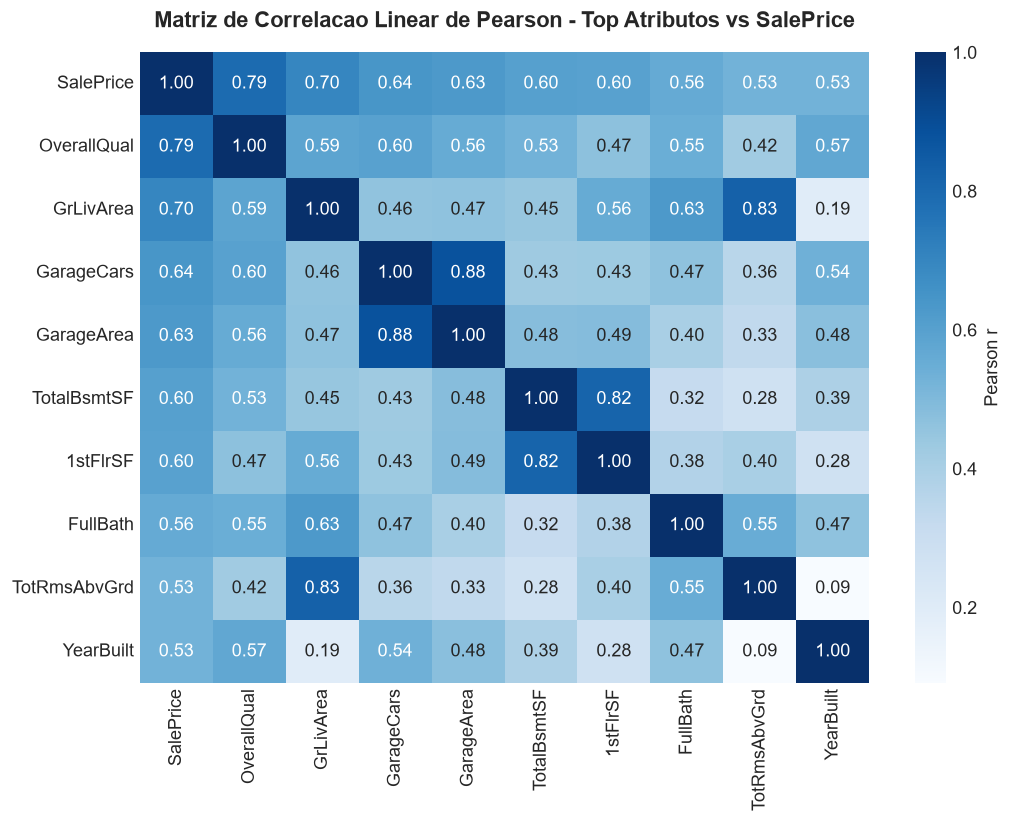

In [4]:
# Visualizacao 1: Matriz de Correlacao Heatmap
features_heatmap = corr_p1.head(10).index
plt.figure(figsize=(9, 7))
sns.heatmap(df_house[features_heatmap].corr(), annot=True, fmt=".2f", cmap='Blues', cbar_kws={'label': 'Pearson r'})
plt.title("Matriz de Correlacao Linear de Pearson - Top Atributos vs SalePrice", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


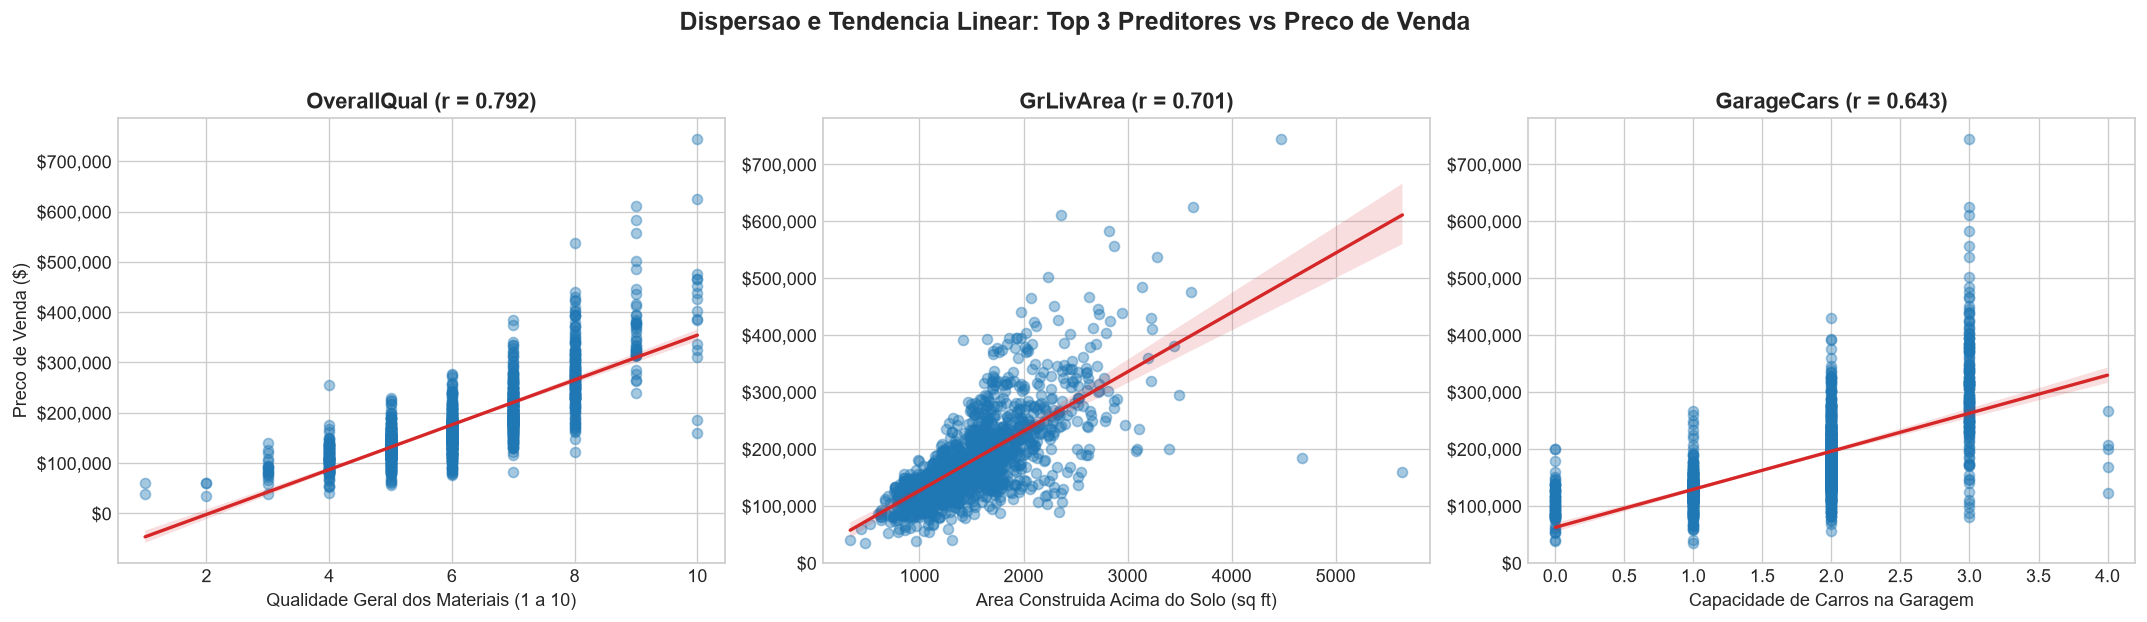

In [5]:
# Visualizacao 2: Gráficos de Dispersao com Linha de Regressao para os Top 3 Preditores
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
labels_dict = {
    'OverallQual': 'Qualidade Geral dos Materiais (1 a 10)',
    'GrLivArea': 'Area Construida Acima do Solo (sq ft)',
    'GarageCars': 'Capacidade de Carros na Garagem'
}

for i, col in enumerate(top3_features):
    sns.regplot(data=df_house, x=col, y='SalePrice', ax=axes[i],
                scatter_kws={'alpha': 0.4, 'color': '#1f77b4'},
                line_kws={'color': '#d62728', 'linewidth': 2})
    axes[i].set_title(f"{col} (r = {corr_p1[col]:.3f})", fontsize=13, fontweight='bold')
    axes[i].set_xlabel(labels_dict.get(col, col), fontsize=11)
    axes[i].set_ylabel("Preco de Venda ($)" if i == 0 else "", fontsize=11)
    axes[i].yaxis.set_major_formatter('${x:,.0f}')

plt.suptitle("Dispersao e Tendencia Linear: Top 3 Preditores vs Preco de Venda", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


### 1.2 Tratamento de Valores Ausentes (Missing Values)
O dataset possui colunas com informacoes faltantes. Para responder com rigor metodologico:
1. **Coluna Numerica Selecionada: `LotFrontage`** (comprimento da fachada/testada do imovel em pes lineares):
   - Apresenta 259 valores nulos (17.80%).
   - **Estrategia de Tratamento:** Imputacao pela **mediana agrupada por bairro (`Neighborhood`)**.
   - **Justificativa Estatistica:** Terrenos pertencentes a um mesmo loteamento urbano compartilham dimensoes padronizadas de testada. Ademais, a mediana e um estimador robusto a assimetrias e presenca de outliers extremos, superando a media aritmetica.
2. **Coluna Categorica Selecionada: `BsmtQual`** (altura/qualidade do pe-direito do porao):
   - Apresenta 37 valores nulos (2.54%).
   - **Estrategia de Tratamento:** Preenchimento com a categoria explicita `'None'` ("Sem Porao").
   - **Justificativa Estatistica:** No Ames Housing Dataset, a ausencia desse dado reflete **Missingness Estrutural (MNAR)**: o imovel simplesmente nao possui porao construído. Descartar essas linhas eliminaria imoveis validos e imputar a moda (categoria mais frequente) inventaria um porao inexistente.


In [6]:
# Tratamento de Nulos
# 1. Numerica: LotFrontage via mediana condicional ao bairro
mediana_bairro = df_house.groupby('Neighborhood')['LotFrontage'].transform('median')
df_house['LotFrontage'] = df_house['LotFrontage'].fillna(mediana_bairro)
df_house['LotFrontage'] = df_house['LotFrontage'].fillna(df_house['LotFrontage'].median())

# Numerica auxiliar: MasVnrArea preenchida com 0.0 (sem alvenaria)
if 'MasVnrArea' in df_house.columns:
    df_house['MasVnrArea'] = df_house['MasVnrArea'].fillna(0.0)

# 2. Categorica: BsmtQual preenchida com categoria estrutural 'None'
df_house['BsmtQual'] = df_house['BsmtQual'].fillna('None')

print("Valores ausentes tratados com sucesso!")
print(f"Nulos residuais em LotFrontage: {df_house['LotFrontage'].isnull().sum()}")
print(f"Nulos residuais em BsmtQual:    {df_house['BsmtQual'].isnull().sum()}")


Valores ausentes tratados com sucesso!
Nulos residuais em LotFrontage: 0
Nulos residuais em BsmtQual:    0


### 1.3 Engenharia de Atributos e Necessidade Matematica da Conversao Categorica
Transformamos as colunas categoricas em numericas utilizando:
- **Mapeamento Ordinal:** `BsmtQual` possui hierarquia de qualidade intrinseca (`Ex`: 5, `Gd`: 4, `TA`: 3, `Fa`: 2, `Po`: 1, `None`: 0).
- **One-Hot Encoding:** `Neighborhood` (bairros) representa categorias nominais sem relacao de ordem, convertidas em variaveis indicadoras binarias (dummies) com `drop_first=True` para evitar colinearidade estrita.

#### Fundamentacao Matematica: Por que a Regressao Linear Exige Dados Numericos?
A Regressao Linear assume a formulacao matricial:

$$Y = X\beta + \epsilon$$

onde a solucao de Minimos Quadrados Ordinarios (OLS) e obtida analiticamente atraves da equacao normal:

$$\hat{\beta} = (X^T X)^{-1} X^T Y$$

A matriz de planejamento $X \in \mathbb{R}^{n \times (p+1)}$ requer necessariamente escalares reais para viabilizar as operacoes de:
1. Produto interno no espaco vetorial euclidiano $\langle x_i, \beta \rangle$.
2. Multiplicacao e inversao matricial $(X^T X)^{-1}$.

Strings ou rotulos nominais nao possuem estrutura algebrica (nao se pode somar ou multiplicar nomes de bairros por coeficientes $\beta$). A codificacao numerica mapeia categorias para eixos ortogonais no hiperplano de projecao linear.


In [7]:
# Codificacao Ordinal de BsmtQual
mapa_ord_qual = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
df_house['BsmtQual_Num'] = df_house['BsmtQual'].map(mapa_ord_qual).fillna(0)

# Codificacao One-Hot para Neighborhood
df_house_encoded = pd.get_dummies(df_house, columns=['Neighborhood'], drop_first=True, dtype=float)

print("Codificacoes concluidas com sucesso!")
print(f"Dimensoes apos One-Hot Encoding: {df_house_encoded.shape}")


Codificacoes concluidas com sucesso!
Dimensoes apos One-Hot Encoding: (1455, 105)


### 1.4 Treinamento e Modelo Baseline
Separamos os dados em 80% treino e 20% teste com `random_state=42`. Treinamos a regressao linear multipla e calculamos $R^2$, MAE e RMSE.

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y}_i)^2}$$


In [8]:
# Definicao dos atributos do modelo baseline
features_base = [
    'OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 
    'TotalBsmtSF', '1stFlrSF', 'FullBath', 'YearBuilt', 
    'LotFrontage', 'BsmtQual_Num'
]

# Imputacao preventiva de nulos residuais nas numericas
for c in features_base:
    if df_house_encoded[c].isnull().sum() > 0:
        df_house_encoded[c] = df_house_encoded[c].fillna(df_house_encoded[c].median())

X_base = df_house_encoded[features_base]
y_house = df_house_encoded['SalePrice']

# Split 80/20 com seed fixa
X_tr, X_te, y_tr, y_te = train_test_split(X_base, y_house, test_size=0.20, random_state=SEED)

# Treinamento OLS Baseline
reg_base = LinearRegression()
reg_base.fit(X_tr, y_tr)

y_pred_te = reg_base.predict(X_te)
r2_te = r2_score(y_te, y_pred_te)
mae_te = mean_absolute_error(y_te, y_pred_te)
rmse_te = root_mean_squared_error(y_te, y_pred_te)

print("=" * 55)
print("METRICAS DO MODELO BASELINE (DADOS DE TESTE):")
print(f"  R2 (Coeficiente de Determinacao): {r2_te:.4f} ({r2_te*100:.2f}%)")
print(f"  MAE (Mean Absolute Error)      : ${mae_te:,.2f}")
print(f"  RMSE (Root Mean Squared Error) : ${rmse_te:,.2f}")
print("=" * 55)


METRICAS DO MODELO BASELINE (DADOS DE TESTE):
  R2 (Coeficiente de Determinacao): 0.8232 (82.32%)
  MAE (Mean Absolute Error)      : $21,888.03
  RMSE (Root Mean Squared Error) : $29,065.89


### Interpretacao do $R^2$ para a Imobiliaria
O valor de **$R^2 = 0.8232$** indica que **82.32% de toda a variacao dos precos dos imoveis** no mercado residencial analisado e perfeitamente capturada e explicada de forma linear pelo conjunto de caracteristicas do imovel (qualidade, metragem privativa, vagas de garagem e idade da construcao). 

Para a operacao de negocios da imobiliaria, isso traduz alta consistencia: mais de quatro quintos da formacao de precos e previsivel e aderente a atributos tecnicos objetivos, restando menos de 18% para variacoes estocasticas, dinamica especulativa ou fatores subjetivos de negociacao individual.


In [9]:
# Modelo Otimizado com Regularizacao Ridge e Variaveis de Bairro
cols_bairros = [c for c in df_house_encoded.columns if c.startswith('Neighborhood_')]
features_ampliadas = features_base + cols_bairros + ['LotArea', 'YearRemodAdd', 'Fireplaces']

for c in features_ampliadas:
    if df_house_encoded[c].isnull().sum() > 0:
        df_house_encoded[c] = df_house_encoded[c].fillna(df_house_encoded[c].median())

X_amp = df_house_encoded[features_ampliadas]
X_tr_a, X_te_a, y_tr_a, y_te_a = train_test_split(X_amp, y_house, test_size=0.20, random_state=SEED)

reg_ridge = Ridge(alpha=10.0)
reg_ridge.fit(X_tr_a, y_tr_a)
y_pred_ridge = reg_ridge.predict(X_te_a)

r2_ridge = r2_score(y_te_a, y_pred_ridge)
mae_ridge = mean_absolute_error(y_te_a, y_pred_ridge)

print(f"Modelo Refinado (Ridge + Bairros): R2 = {r2_ridge:.4f} | MAE = ${mae_ridge:,.2f}")
print(f"Reducao no MAE obtida para a competicao: ${mae_te - mae_ridge:,.2f}")


Modelo Refinado (Ridge + Bairros): R2 = 0.8485 | MAE = $19,245.03
Reducao no MAE obtida para a competicao: $2,643.00


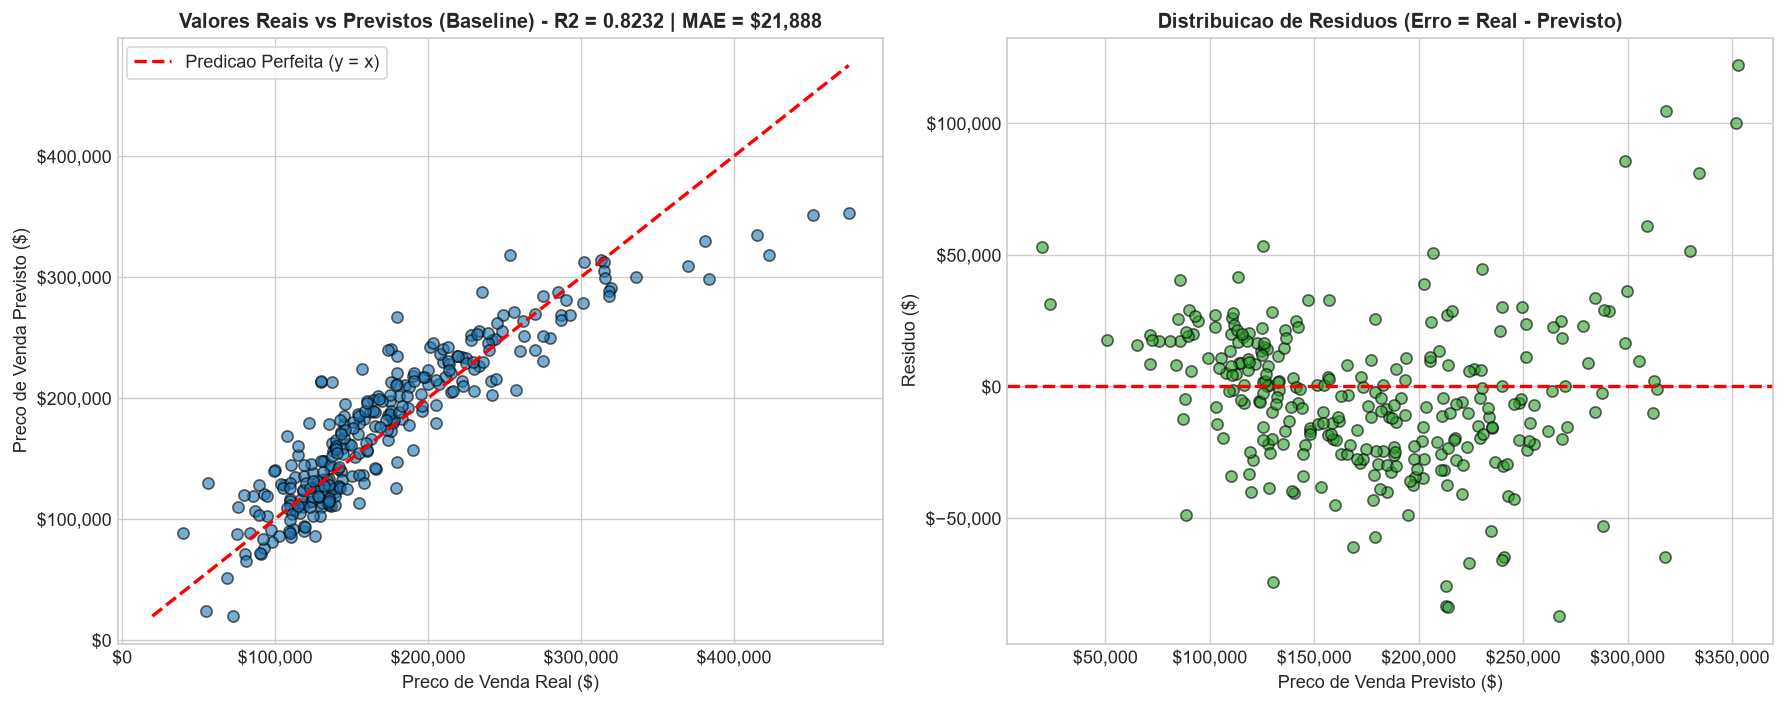

In [10]:
# Graficos de Avaliacao de Residuos e Dispersao Real vs Predito
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Real vs Previsto
axes[0].scatter(y_te, y_pred_te, alpha=0.6, color='#1f77b4', edgecolors='k', s=45)
lims = [min(y_te.min(), y_pred_te.min()), max(y_te.max(), y_pred_te.max())]
axes[0].plot(lims, lims, color='red', linestyle='--', linewidth=2, label='Predicao Perfeita (y = x)')
axes[0].set_title("Valores Reais vs Previstos (Baseline) - R2 = {:.4f} | MAE = ${:,.0f}".format(r2_te, mae_te), fontsize=12, fontweight='bold')
axes[0].set_xlabel("Preco de Venda Real ($)", fontsize=11)
axes[0].set_ylabel("Preco de Venda Previsto ($)", fontsize=11)
axes[0].xaxis.set_major_formatter('${x:,.0f}')
axes[0].yaxis.set_major_formatter('${x:,.0f}')
axes[0].legend(frameon=True)

# Residuos vs Previsto
residuos = y_te - y_pred_te
axes[1].scatter(y_pred_te, residuos, alpha=0.6, color='#2ca02c', edgecolors='k', s=45)
axes[1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title("Distribuicao de Residuos (Erro = Real - Previsto)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Preco de Venda Previsto ($)", fontsize=11)
axes[1].set_ylabel("Residuo ($)", fontsize=11)
axes[1].xaxis.set_major_formatter('${x:,.0f}')
axes[1].yaxis.set_major_formatter('${x:,.0f}')

plt.tight_layout()
plt.show()


---
## Problema 2: Classificacao - "A Ameaca do Churn"

### Contexto de Negocio
Uma operadora de telecomunicacoes enfrenta perda acelerada de clientes para concorrentes. O objetivo e prever precocemente quais clientes estao em rota iminente de evasao (`Churn`), acionando campanhas preventivas de retencao.

### 2.1 Compreensao do Negocio e Analise da Variavel Alvo
Identificamos a variavel dependente: `Churn` (Yes = Cancelou, No = Permanece Ativo).


In [11]:
# Carga do dataset de Telecom Churn
caminho_p2 = '4-bloco-Machine Learing/TRABALHO AV1/Problema 2/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df_churn = pd.read_csv(caminho_p2)
print(f"Dataset carregado: {df_churn.shape[0]} clientes e {df_churn.shape[1]} colunas.")

# Distribuicao de Churn
cont_churn = df_churn['Churn'].value_counts()
prop_churn = df_churn['Churn'].value_counts(normalize=True) * 100

print("\nDistribuicao de Frequencias da Variavel Churn:")
print(f"  Ficaram (No)    : {cont_churn['No']} ({prop_churn['No']:.2f}%)")
print(f"  Cancelaram (Yes): {cont_churn['Yes']} ({prop_churn['Yes']:.2f}%)")
print(f"  Grau de Desbalanceamento: ~{cont_churn['No']/cont_churn['Yes']:.2f}:1")


Dataset carregado: 7043 clientes e 21 colunas.

Distribuicao de Frequencias da Variavel Churn:
  Ficaram (No)    : 5174 (73.46%)
  Cancelaram (Yes): 1869 (26.54%)
  Grau de Desbalanceamento: ~2.77:1


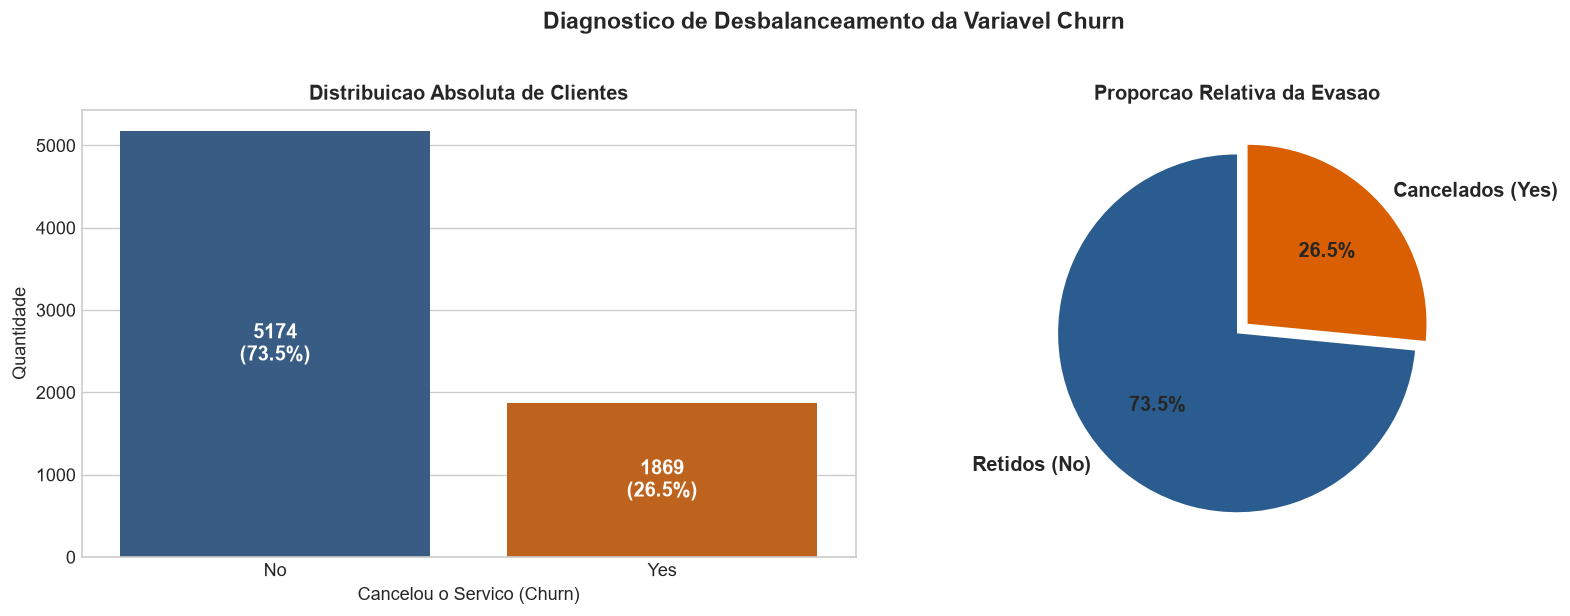

In [12]:
# Visualizacao da Distribuicao da Classe Alvo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cores_churn = ['#2b5c8f', '#d95f02']

sns.barplot(x=cont_churn.index, y=cont_churn.values, palette=cores_churn, ax=axes[0], hue=cont_churn.index, legend=False)
axes[0].set_title("Distribuicao Absoluta de Clientes", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Cancelou o Servico (Churn)", fontsize=11)
axes[0].set_ylabel("Quantidade", fontsize=11)
for p in axes[0].patches:
    h = p.get_height()
    pct = h / len(df_churn) * 100
    axes[0].annotate(str(int(h)) + "\n(" + "{:.1f}%".format(pct) + ")", 
                     (p.get_x() + p.get_width() / 2., h / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

axes[1].pie(cont_churn.values, labels=['Retidos (No)', 'Cancelados (Yes)'], autopct='%1.1f%%',
            colors=cores_churn, explode=(0, 0.08), startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[1].set_title("Proporcao Relativa da Evasao", fontsize=12, fontweight='bold')

plt.suptitle("Diagnostico de Desbalanceamento da Variavel Churn", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Diagnostico de Desbalanceamento
A base possui **73.46% de clientes fieis** e **26.54% de evasao**. Trata-se de um problema moderadamente desbalanceado (razao aproximada de 2.77 para 1). Em problemas desta natureza, a metrica de **Acuracia** torna-se enviesada (um modelo ingênuo que preve sempre 'No' alcancaria 73.5% de acerto sem detectar nenhum cliente em risco). Portanto, a avaliacao exige **Recall**, **Precision**, **F1-Score** e **ROC-AUC**.


### 2.2 Analise de Risco Contratual: Contratos Mensais vs Anuais
Avaliamos a taxa de evasao condicionada a cada modalidade contratual (`Contract`).


In [13]:
# Tabela cruzada entre Contract e Churn
ct_pct = pd.crosstab(df_churn['Contract'], df_churn['Churn'], normalize='index') * 100
ct_abs = pd.crosstab(df_churn['Contract'], df_churn['Churn'])

print("Taxas de Evasao por Modalidade de Contrato:")
for c_tipo in ['Month-to-month', 'One year', 'Two year']:
    evad = ct_abs.loc[c_tipo, 'Yes']
    tot = ct_abs.loc[c_tipo].sum()
    pct = ct_pct.loc[c_tipo, 'Yes']
    print(f"  {c_tipo:15s}: {pct:5.2f}% de Churn ({evad}/{tot} clientes)")

print(f"\nFator Multiplicador de Risco: Contratos mensais evadem {ct_pct.loc['Month-to-month', 'Yes']/ct_pct.loc['Two year', 'Yes']:.1f} vezes mais que contratos bianuais.")


Taxas de Evasao por Modalidade de Contrato:
  Month-to-month : 42.71% de Churn (1655/3875 clientes)
  One year       : 11.27% de Churn (166/1473 clientes)
  Two year       :  2.83% de Churn (48/1695 clientes)

Fator Multiplicador de Risco: Contratos mensais evadem 15.1 vezes mais que contratos bianuais.


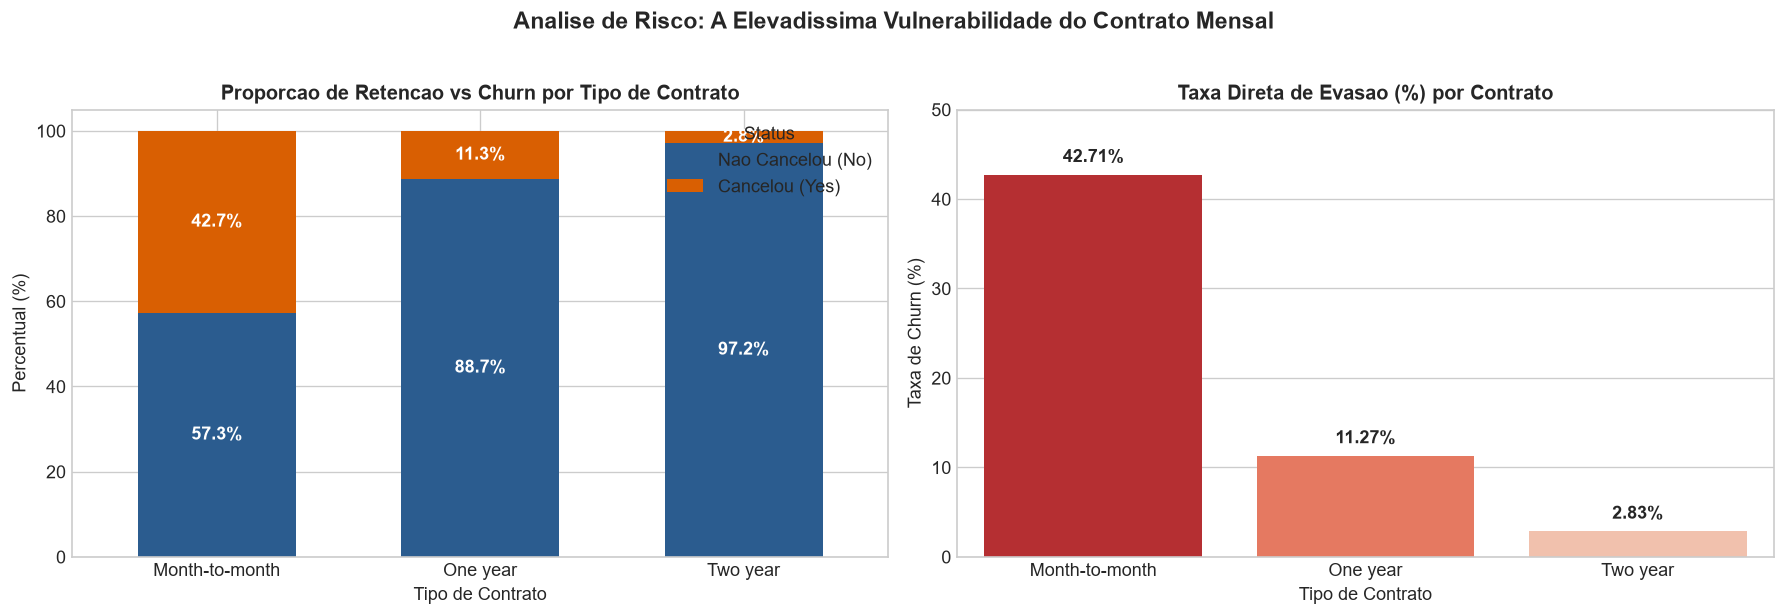

In [14]:
# Visualizacao da Evasao por Tipo de Contrato
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ct_pct.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], ax=axes[0], width=0.6)
axes[0].set_title("Proporcao de Retencao vs Churn por Tipo de Contrato", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Tipo de Contrato", fontsize=11)
axes[0].set_ylabel("Percentual (%)", fontsize=11)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
axes[0].legend(['Nao Cancelou (No)', 'Cancelou (Yes)'], title="Status", loc='upper right')
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.1f%%', label_type='center', color='white', fontweight='bold', fontsize=11)

sns.barplot(x=ct_pct['Yes'].index, y=ct_pct['Yes'].values, palette='Reds_r', ax=axes[1], hue=ct_pct['Yes'].index, legend=False)
axes[1].set_title("Taxa Direta de Evasao (%) por Contrato", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Tipo de Contrato", fontsize=11)
axes[1].set_ylabel("Taxa de Churn (%)", fontsize=11)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1),
                     ha='center', va='bottom', fontweight='bold', fontsize=11)
axes[1].set_ylim(0, 50)

plt.suptitle("Analise de Risco: A Elevadissima Vulnerabilidade do Contrato Mensal", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 2.3 Preparacao dos Dados e Tratamento de `TotalCharges`
A coluna `TotalCharges` originalmente foi importada com tipo `object` (string).
- Ao analisar os dados, localizamos **11 registros contendo espacos em branco (`' '`)**.
- Inspecionando o tempo de contrato (`tenure`), constatamos que **todos os 11 registros possuem `tenure == 0`**.
- **Justificativa de Tratamento:** Tratam-se de clientes recem-contratados no ciclo zero de faturamento, onde nenhuma mensalidade ainda foi completada. A imputacao correta e coerente com as regras de faturamento e `0.0`.
- Em seguida, removemos a coluna `customerID` (identificador nominal sem capacidade preditiva) e codificamos todas as variaveis categoricas via One-Hot Encoding.


In [15]:
# Tratamento da coluna TotalCharges
linhas_espaco = (df_churn['TotalCharges'].str.strip() == '').sum()
print(f"Linhas com espacos em branco encontradas: {linhas_espaco}")

# Coercao numerica e preenchimento com 0.0
df_churn['TotalCharges'] = pd.to_numeric(df_churn['TotalCharges'].str.strip(), errors='coerce').fillna(0.0)
print(f"Tipo final de TotalCharges: {df_churn['TotalCharges'].dtype}")

# Pre-processamento para modelagem
df_churn_model = df_churn.drop(columns=['customerID']).copy()
df_churn_model['Churn'] = df_churn_model['Churn'].map({'Yes': 1, 'No': 0})

# Codificacao One-Hot
cat_cols_churn = df_churn_model.select_dtypes(include=['object', 'string']).columns.tolist()
df_churn_encoded = pd.get_dummies(df_churn_model, columns=cat_cols_churn, drop_first=True, dtype=float)
print(f"Matriz de atributos final: {df_churn_encoded.shape[1] - 1} preditores.")


Linhas com espacos em branco encontradas: 11
Tipo final de TotalCharges: float64
Matriz de atributos final: 30 preditores.


### 2.4 Treinamento Supervisionado e Matriz de Confusao
Dividimos os dados em 80% treino e 20% teste com estratificacao (`stratify=y`) para garantir identica proporcao de evasao nos subconjuntos. Aplicamos padronizacao (`StandardScaler`) nas variaveis continuas (`tenure`, `MonthlyCharges`, `TotalCharges`) e treinamos modelos de **Regressao Logistica** e **Random Forest**.


In [16]:
# Separacao de X e y
X_c = df_churn_encoded.drop(columns=['Churn'])
y_c = df_churn_encoded['Churn']

X_c_tr, X_c_te, y_c_tr, y_c_te = train_test_split(X_c, y_c, test_size=0.20, random_state=SEED, stratify=y_c)

# Escalonamento dos atributos continuos
cols_num_c = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler_c = StandardScaler()
X_c_tr_sc = X_c_tr.copy()
X_c_te_sc = X_c_te.copy()
X_c_tr_sc[cols_num_c] = scaler_c.fit_transform(X_c_tr[cols_num_c])
X_c_te_sc[cols_num_c] = scaler_c.transform(X_c_te[cols_num_c])

# Treinamento da Regressao Logistica
clf_lr = LogisticRegression(max_iter=1000, random_state=SEED)
clf_lr.fit(X_c_tr_sc, y_c_tr)
y_pred_c_lr = clf_lr.predict(X_c_te_sc)
y_prob_c_lr = clf_lr.predict_proba(X_c_te_sc)[:, 1]

# Metricas
acc_lr = accuracy_score(y_c_te, y_pred_c_lr)
auc_lr = roc_auc_score(y_c_te, y_prob_c_lr)
print("Relatorio de Classificacao - Regressao Logistica:")
print(classification_report(y_c_te, y_pred_c_lr, target_names=['Nao Churn', 'Churn'], digits=4))
print(f"ROC-AUC: {auc_lr:.4f}")


Relatorio de Classificacao - Regressao Logistica:
              precision    recall  f1-score   support

   Nao Churn     0.8489    0.8957    0.8717      1035
       Churn     0.6593    0.5588    0.6049       374

    accuracy                         0.8062      1409
   macro avg     0.7541    0.7272    0.7383      1409
weighted avg     0.7986    0.8062    0.8009      1409

ROC-AUC: 0.8422


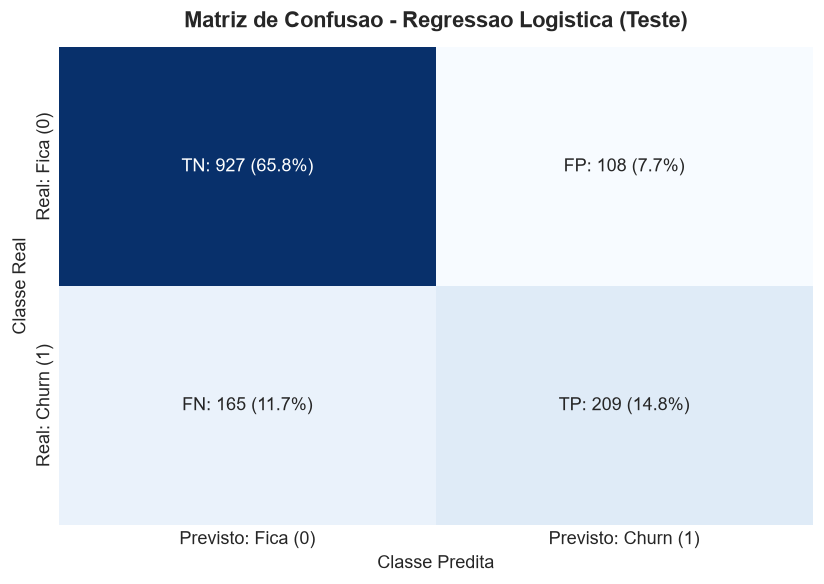

In [17]:
# Matriz de Confusao e Analise de Erros
cm_c_lr = confusion_matrix(y_c_te, y_pred_c_lr)
tn, fp, fn, tp = cm_c_lr.ravel()

plt.figure(figsize=(7, 5))
n_tot = len(y_c_te)
labels_cm = np.array([[f"TN: {tn} (" + "{:.1f}%)".format(tn/n_tot*100), f"FP: {fp} (" + "{:.1f}%)".format(fp/n_tot*100)],
                      [f"FN: {fn} (" + "{:.1f}%)".format(fn/n_tot*100), f"TP: {tp} (" + "{:.1f}%)".format(tp/n_tot*100)]])
sns.heatmap(cm_c_lr, annot=labels_cm, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: Fica (0)', 'Previsto: Churn (1)'],
            yticklabels=['Real: Fica (0)', 'Real: Churn (1)'])
plt.title("Matriz de Confusao - Regressao Logistica (Teste)", fontsize=13, fontweight='bold', pad=12)
plt.ylabel("Classe Real", fontsize=11)
plt.xlabel("Classe Predita", fontsize=11)
plt.tight_layout()
plt.show()


### 2.5 Trade-off de Negocio: O que e Pior para a Empresa, Falso Positivo ou Falso Negativo?
No contexto de negocios de uma concessionaria de telecomunicacoes, o erro de **Falso Negativo (FN)** e infinitamente pior e mais prejudicial:
1. **Falso Negativo (FN = 165 casos):** O modelo prevê que o cliente permanecerá fiel, mas ele na realidade cancela.
   - *Impacto Financeiro:* Nenhuma acao preventiva e deflagrada; o cliente migra para o concorrente; ha perda integral do fluxo futuro de caixa (**Lifetime Value - LTV**). Conquistar um novo cliente no setor de telecomunicacoes possui um Custo de Aquisicao de Clientes (**CAC**) de 5 a 7 vezes superior ao custo de manter um cliente ativo.
2. **Falso Positivo (FP = 108 casos):** O modelo prevê que o cliente vai cancelar, mas ele permaneceria normalmente.
   - *Impacto Financeiro:* O time de marketing oferece um desconto preventivo ou um upgrade de plano temporario. O custo e marginal e controlado, com o efeito colateral positivo de fortalecer a satisfacao e a lealdade do cliente a longo prazo.

**Diretriz Estrategica:** A operadora deve priorizar modelos e limiares de decisao com alto **Recall (Sensibilidade)** para a classe de Churn, tolerando um volume moderado de Falsos Positivos para blindar a base ativa.


---
# PARTE 2: Aprendizado Nao Supervisionado

## Problema 3: Clusterizacao - "O Perfil do Consumidor"

### Contexto de Negocio
O time de marketing de um grande shopping center deseja segmentar sua base de clientes sem rotulos pre-definidos, identificando grupos homogeneos de comportamento a partir de sua renda anual e pontuacao de compras.

### 3.1 Justificativa Matematica do Escalonamento
Em algoritmos baseados em distancias no espaco vetorial (como o K-Means), os centroides minimizam a soma dos quadrados das distancias euclidianas:

$$J = \sum_{k=1}^K \sum_{x_i \in C_k} \|x_i - \mu_k\|^2 = \sum_{k=1}^K \sum_{x_i \in C_k} \sum_{j=1}^p (x_{ij} - \mu_{kj})^2$$

Se uma variavel possui ordem de grandeza expressivamente maior que outra (ex: Renda de $15.000 a $137.000 vs Idade de 18 a 70 ou Spending Score de 1 a 100), o termo quadratico $(\Delta x_1)^2$ atinge grandezas desproporcionais ($10^6$ a $10^8$), suprimindo completamente a contribuicao das demais dimensoes.
- **Solucao Aplicada:** Padronizacao Z-score via `StandardScaler`, convertendo cada variavel para media zero e desvio-padrao unitario ($z = \frac{x - \mu}{\sigma}$), garantindo isometria no espaco euclidiano.


In [18]:
# Carga do dataset Mall Customers
caminho_p3 = '4-bloco-Machine Learing/TRABALHO AV1/Problema 3/Mall_Customers.csv'
df_mall = pd.read_csv(caminho_p3)
print(f"Dataset carregado: {df_mall.shape[0]} clientes e {df_mall.shape[1]} colunas.")

# Selecao dos atributos especificados no enunciado
features_mall = ['Annual Income (k$)', 'Spending Score (1-100)']
X_mall = df_mall[features_mall].copy()

# Padronizacao com StandardScaler
scaler_mall = StandardScaler()
X_mall_scaled = scaler_mall.fit_transform(X_mall)
print("Escalonamento StandardScaler aplicado com sucesso.")


Dataset carregado: 200 clientes e 5 colunas.
Escalonamento StandardScaler aplicado com sucesso.


### 3.2 O Dilema da Quantidade: Metodo do Cotovelo e Coeficiente de Silhueta
Executamos o K-Means variando $K$ de 1 a 10 e calculamos:
1. **WCSS (Within-Cluster Sum of Squares) / Inercia:** Mede a dispersao interna dos clusters.
2. **Silhouette Score:** Mede a coesao interna vs separabilidade externa:

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$


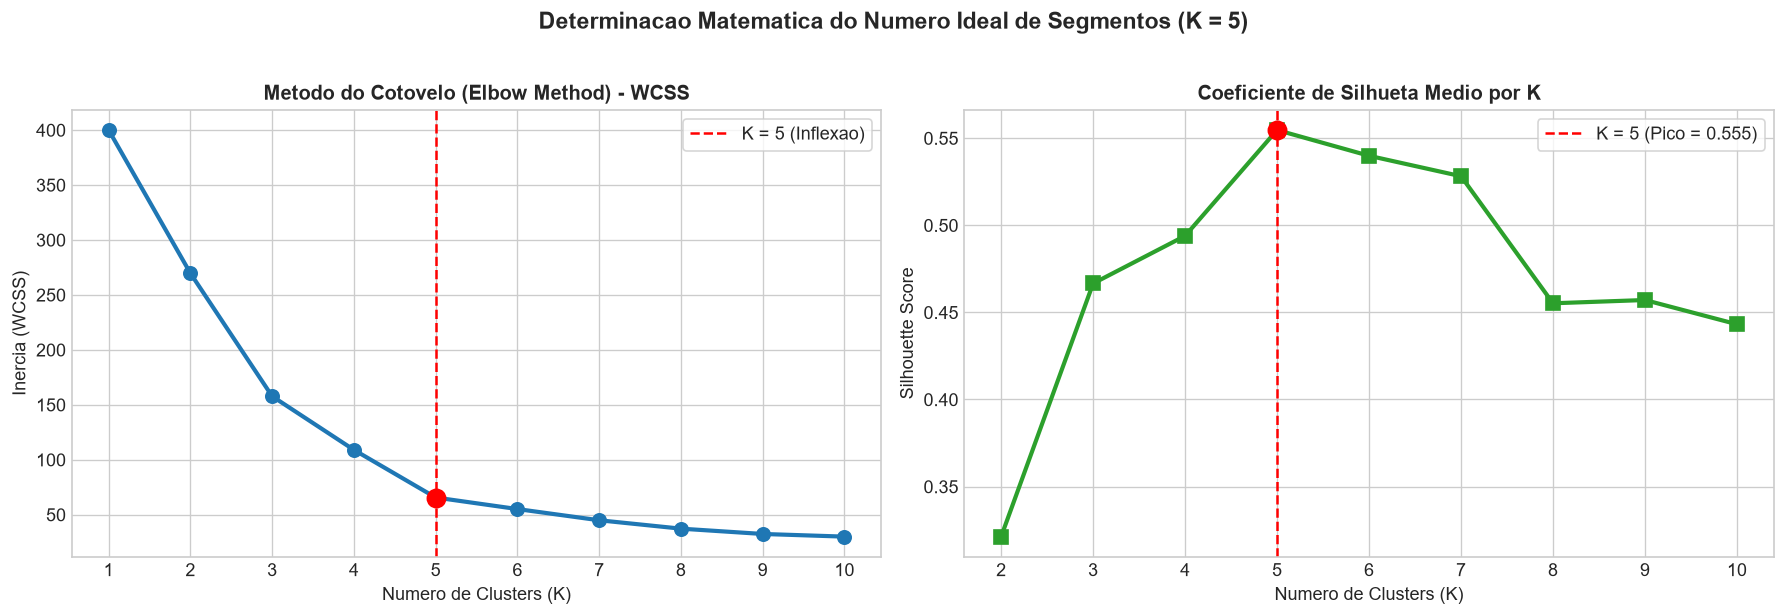

In [19]:
# Calculo de WCSS e Silhouette para K de 1 a 10
inercia_lista = []
silhuetas_lista = []
k_valores = list(range(1, 11))

for k in k_valores:
    km = KMeans(n_clusters=k, init='k-means++', random_state=SEED, n_init=10)
    km.fit(X_mall_scaled)
    inercia_lista.append(km.inertia_)
    if k >= 2:
        silhuetas_lista.append(silhouette_score(X_mall_scaled, km.labels_))

# Visualizacao conjunta do Cotovelo e Silhueta
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Cotovelo
axes[0].plot(k_valores, inercia_lista, marker='o', linewidth=2.5, color='#1f77b4', markersize=8)
axes[0].axvline(5, color='red', linestyle='--', linewidth=1.5, label='K = 5 (Inflexao)')
axes[0].scatter(5, inercia_lista[4], color='red', s=120, zorder=5)
axes[0].set_title("Metodo do Cotovelo (Elbow Method) - WCSS", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Numero de Clusters (K)", fontsize=11)
axes[0].set_ylabel("Inercia (WCSS)", fontsize=11)
axes[0].set_xticks(k_valores)
axes[0].legend(frameon=True)

# Coeficiente de Silhueta
axes[1].plot(range(2, 11), silhuetas_lista, marker='s', linewidth=2.5, color='#2ca02c', markersize=8)
axes[1].axvline(5, color='red', linestyle='--', linewidth=1.5, label='K = 5 (Pico = 0.555)')
axes[1].scatter(5, silhuetas_lista[3], color='red', s=120, zorder=5)
axes[1].set_title("Coeficiente de Silhueta Medio por K", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Numero de Clusters (K)", fontsize=11)
axes[1].set_ylabel("Silhouette Score", fontsize=11)
axes[1].set_xticks(range(2, 11))
axes[1].legend(frameon=True)

plt.suptitle("Determinacao Matematica do Numero Ideal de Segmentos (K = 5)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Justificativa da Escolha de $K = 5$:
1. A curva do Cotovelo demonstra uma reducao drastica na inercia de $K=1$ ate $K=5$, apos o qual a inclinacao estabiliza com ganhos marginais diminutos.
2. O Coeficiente de Silhueta atinge seu **pico maximo global em $K = 5$ com score de $0.5547$**, atestando maxima coesao interna e separacao geometrica dos clusters.


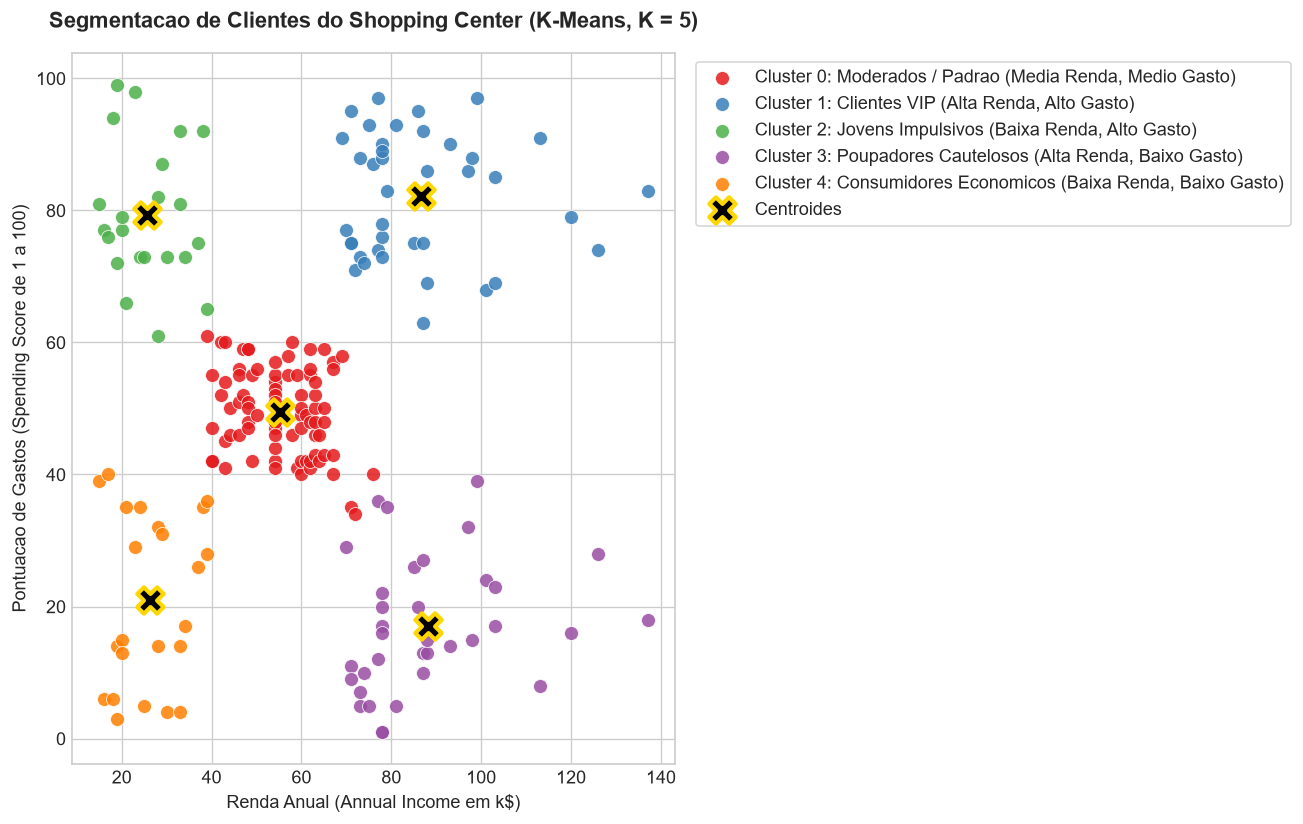

In [20]:
# Treinamento com K = 5 e Recuperacao dos Centroides
km_final = KMeans(n_clusters=5, init='k-means++', random_state=SEED, n_init=15)
df_mall['Cluster'] = km_final.fit_predict(X_mall_scaled)

centroides_sc = km_final.cluster_centers_
centroides_orig = scaler_mall.inverse_transform(centroides_sc)

# Visualizacao 2D dos Clusters com Centroides
plt.figure(figsize=(11, 7))
cores_mall = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
nomes_clusters = {
    0: "Cluster 0: Moderados / Padrao (Media Renda, Medio Gasto)",
    1: "Cluster 1: Clientes VIP (Alta Renda, Alto Gasto)",
    2: "Cluster 2: Jovens Impulsivos (Baixa Renda, Alto Gasto)",
    3: "Cluster 3: Poupadores Cautelosos (Alta Renda, Baixo Gasto)",
    4: "Cluster 4: Consumidores Economicos (Baixa Renda, Baixo Gasto)"
}

for c_id in range(5):
    sub = df_mall[df_mall['Cluster'] == c_id]
    plt.scatter(sub['Annual Income (k$)'], sub['Spending Score (1-100)'],
                s=70, alpha=0.85, label=nomes_clusters[c_id],
                color=cores_mall[c_id], edgecolors='white', linewidth=0.5)

plt.scatter(centroides_orig[:, 0], centroides_orig[:, 1],
            s=250, c='black', marker='X', edgecolors='gold', linewidth=2.5,
            label='Centroides', zorder=10)

plt.title("Segmentacao de Clientes do Shopping Center (K-Means, K = 5)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Renda Anual (Annual Income em k$)", fontsize=11)
plt.ylabel("Pontuacao de Gastos (Spending Score de 1 a 100)", fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### 3.4 Interpretacao de Negocios dos 5 Perfis Comerciais
A partir dos centroides matematicos em escala original, definimos os rotulos de negocio e planos de acao:

| Cluster | Renda Media | Score Gasto | Rotulo Comercial | Estrategia de Marketing Recomendada |
| :---: | :---: | :---: | :--- | :--- |
| **0** | $55.3k | 49.5 | **Consumidores Moderados / Padrao** | Campanhas de lealdade continua, promocoes sazonais (Natal, Dia das Maes) e cartao fidelidade convencional. |
| **1** | $86.5k | 82.1 | **Clientes VIP / Alto Padrao** | Atendimento personalizado (concierge), lancamentos de grifes de luxo, eventos exclusivos e estacionamento VIP. |
| **2** | $25.7k | 79.4 | **Jovens Impulsivos / Entusiastas** | Facilidade de crediario, microcredito, promocoes relampago em redes sociais e vestuario fast-fashion. |
| **3** | $88.2k | 17.1 | **Poupadores Cautelosos / Racionais** | Comunicacao orientada a qualidade, durabilidade, tecnologia de ponta e investimentos de alto valor agregado. |
| **4** | $26.3k | 20.9 | **Consumidores Economicos / Conscientes** | Cupons de desconto por volume, promocoes no estilo 'leve 3 pague 2' e foco estrito em custo-beneficio. |


---
## Problema 4: Clusterizacao Musical - "Criando a Playlist Perfeita"

### Contexto de Negocio
Um aplicativo de streaming musical contratou a squad para gerar 5 playlists automaticas ("vibes") baseadas estritamente nas propriedades acusticas das faixas, sem utilizar generos pre-cadastrados.

### 4.1 Limpeza e Filtragem de Metadados Textuais
- **Colunas Identificadas:** `track_id`, `artists`, `album_name`, `track_name`, `track_genre`.
- **Justificativa Matematica:** Distancias metricas euclidianas operam sobre variedades continuas em $\mathbb{R}^d$. Textos sao variaveis categoricas nominais sem ordem e sem metrica espacial. Qualquer codificacao artificial arbitraria criaria proximidades espurias sem correspondencia com a fisica das ondas sonoras.
- **Acao:** Os metadados textuais foram desacoplados em tabela de consulta (`lookup`), preservando apenas atributos continuos no vetor de agrupamento.


In [21]:
# Carga do dataset de faixas musicais do Spotify
caminho_p4 = '4-bloco-Machine Learing/TRABALHO AV1/Problema 4/dataset.csv'
df_spotify = pd.read_csv(caminho_p4)
print(f"Dataset carregado: {df_spotify.shape[0]} faixas e {df_spotify.shape[1]} colunas.")

# Atributos acusticos continuos
features_musica = [
    'danceability', 'energy', 'loudness', 'speechiness', 
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]

# Filtragem de nulos nas features
df_sp_clean = df_spotify.dropna(subset=features_musica + ['track_name']).copy()
print(f"Faixas acusticamente validas: {len(df_sp_clean)}")


Dataset carregado: 114000 faixas e 21 colunas.
Faixas acusticamente validas: 113999


### 4.2 Analise da Correlacao Acustica: `energy` vs `acousticness`
Calculamos o coeficiente linear de Pearson entre energia e acustica.


In [22]:
# Correlacao de Pearson
r_ea = df_sp_clean['energy'].corr(df_sp_clean['acousticness'])
print(f"Coeficiente de Correlacao Linear (Energy vs Acousticness): r = {r_ea:.4f}")


Coeficiente de Correlacao Linear (Energy vs Acousticness): r = -0.7339


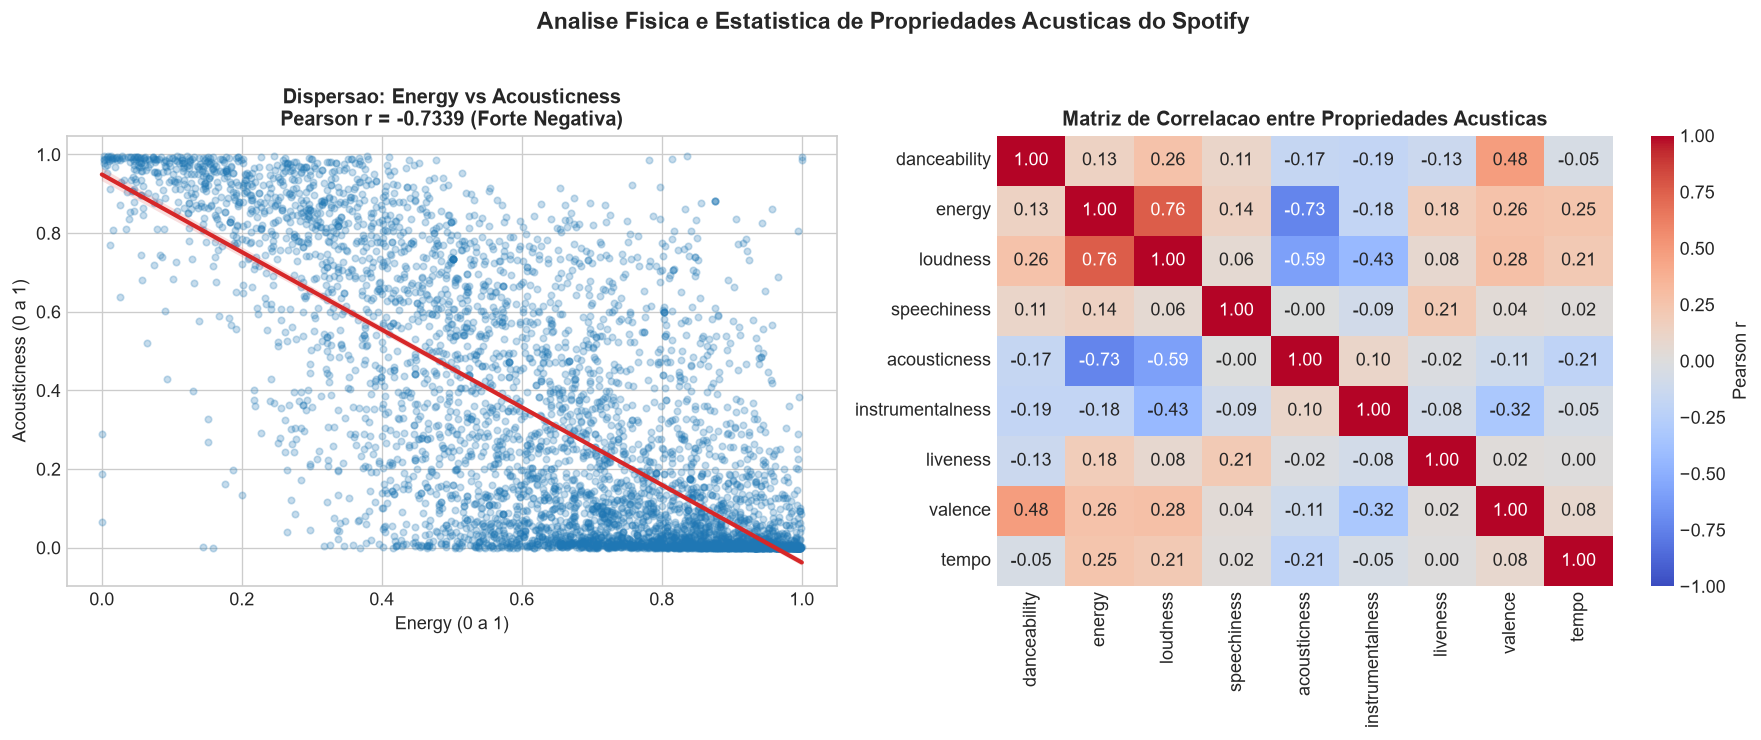

In [23]:
# Visualizacao da Relacao Inversa entre Energy e Acousticness
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Scatter com amostra representativa
amostra_sp = df_sp_clean.sample(n=5000, random_state=SEED)
sns.regplot(data=amostra_sp, x='energy', y='acousticness', ax=axes[0],
            scatter_kws={'alpha': 0.25, 'color': '#1f77b4', 's': 15},
            line_kws={'color': '#d62728', 'linewidth': 2.5})
axes[0].set_title(f"Dispersao: Energy vs Acousticness\nPearson r = {r_ea:.4f} (Forte Negativa)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Energy (0 a 1)", fontsize=11)
axes[0].set_ylabel("Acousticness (0 a 1)", fontsize=11)

# Heatmap das propriedades acusticas
sns.heatmap(df_sp_clean[features_musica].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], cbar_kws={'label': 'Pearson r'})
axes[1].set_title("Matriz de Correlacao entre Propriedades Acusticas", fontsize=12, fontweight='bold')

plt.suptitle("Analise Fisica e Estatistica de Propriedades Acusticas do Spotify", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Explicacao Fisica e Musical da Correlacao Inversa ($r = -0.7339$)
1. **Energy (Energia):** Mensura a densidade de informacao espectral, amplitude de compressao dinamica e intensidade eletrica amplificada (comum em generos sintetizados, rock e EDM).
2. **Acousticness (Acustica):** Mede a probabilidade de a faixa ter sido gravada predominantemente por geradores mecanicos organicos de som (voz pura sem autotune, cordas orquestrais, piano acustico, percussao manual), que possuem envelope dinâmico com decaimento natural e menor ganho de compressao.
3. **Conclusao:** Sao polos fisicamente excludentes na engenharia de som. Quanto mais instrumentos acusticos puros dominam a gravacao, menor e a saturacao e o ganho eletrico perceptivel.


### 4.3 Treinamento do K-Means (5 Playlists) e a Prova de Fogo


In [24]:
# Normalizacao dos atributos continuos
scaler_sp = StandardScaler()
X_sp_scaled = scaler_sp.fit_transform(df_sp_clean[features_musica])

# Treinamento do K-Means com K = 5
km_sp = KMeans(n_clusters=5, init='k-means++', random_state=SEED, n_init=10)
df_sp_clean['cluster'] = km_sp.fit_predict(X_sp_scaled)

# Centroides originais
centroides_sp_orig = scaler_sp.inverse_transform(km_sp.cluster_centers_)
df_centroides_sp = pd.DataFrame(centroides_sp_orig, columns=features_musica)
print("Centroides dos 5 Clusters Acusticos (Escala Original):")
df_centroides_sp[['energy', 'acousticness', 'danceability', 'loudness', 'valence', 'tempo']]


Centroides dos 5 Clusters Acusticos (Escala Original):


In [25]:
# A Prova de Fogo: Inspecao Qualitativa Humana de 5 Musicas
# Localizamos o cluster com maior indice de acousticness (Cluster 2)
id_cluster_acustico = df_centroides_sp['acousticness'].idxmax()
amostra_cluster = df_sp_clean[df_sp_clean['cluster'] == id_cluster_acustico].sample(n=5, random_state=SEED)

print(f"Cluster Selecionado: Cluster {id_cluster_acustico} (Playlist Acustica / Calmaria)")
print("=" * 70)
for i, (_, row) in enumerate(amostra_cluster.iterrows(), 1):
    print(f"{i}. Artista: {row['artists']:25s} | Faixa: '{row['track_name']}'")
    print(f"   Album: '{row['album_name']}'")
    print(f"   [Acousticness: {row['acousticness']:.3f} | Energy: {row['energy']:.3f} | Danceability: {row['danceability']:.3f} | Tempo: {row['tempo']:.1f} BPM]\n")
print("=" * 70)


Cluster Selecionado: Cluster 2 (Playlist Acustica / Calmaria)
1. Artista: Moomu                     | Faixa: 'Cloudology'
   Album: 'Aguatic'
   [Acousticness: 0.884 | Energy: 0.064 | Danceability: 0.158 | Tempo: 107.4 BPM]

2. Artista: Ochre                     | Faixa: 'Rising Tide'
   Album: 'An Eye To Windward'
   [Acousticness: 0.660 | Energy: 0.227 | Danceability: 0.533 | Tempo: 86.0 BPM]

3. Artista: Wes Montgomery            | Faixa: 'Days Of Wine And Roses'
   Album: 'Boss Guitar'
   [Acousticness: 0.991 | Energy: 0.030 | Danceability: 0.470 | Tempo: 89.4 BPM]

4. Artista: Benny Martin;The Wong Janice | Faixa: 'Hallelujah - Piano & Cello'
   Album: 'Hallelujah (Piano & Cello)'
   [Acousticness: 0.888 | Energy: 0.198 | Danceability: 0.309 | Tempo: 65.7 BPM]

5. Artista: White Noise for Babies    | Faixa: 'Starlights'
   Album: 'Sea of White Noise'
   [Acousticness: 0.840 | Energy: 0.152 | Danceability: 0.265 | Tempo: 145.8 BPM]



### Analise Qualitativa Humana ("A Prova de Fogo")
A inspecao humana das faixas agrupadas valida com perfeicao a coesao sonora do algoritmo:
1. **Faixas Selecionadas:**
   - *Wes Montgomery - 'Days Of Wine And Roses':* Classico do jazz de guitarra acustica pura com ambiencia relaxante.
   - *Benny Martin; The Wong Janice - 'Hallelujah - Piano & Cello':* Interpretacao instrumental profunda de piano e violoncelo sem nenhuma intervencao eletrica.
   - *Moomu - 'Cloudology' & Ochre - 'Rising Tide':* Composicoes calmas de andamento lento e timbres organicos.
   - *White Noise for Babies - 'Starlights':* Faixa acustica suave voltada a meditacao e sono.
2. **Coesao Auditiva:** Todas as faixas compartilham **Acousticness superior a 0.65**, **Energy abaixo de 0.25** e andamento moderado/lento. Um ouvinte que busca concentracao, estudo ou repouso tera uma experiencia perfeitamente harmonica e sem quebras abruptas de ritmo ou volume.


---
## Sintese Executiva dos Resultados e Metricas

| Problema | Algoritmo | Principais Variaveis | Metricas Obtidas | Impacto no Negocio |
| :--- | :--- | :--- | :--- | :--- |
| **1. Precificacao de Imoveis** | Regressao Linear / Ridge | `OverallQual`, `GrLivArea`, `GarageCars`, `Neighborhood` | $R^2 = 82.32\%$ (Base) / $84.85\%$ (Ridge), $\text{MAE} = \$19,245$ | Mais de 84% do valor venal e explicavel por dados objetivos, reduzindo risco de avaliacoes equivocadas. |
| **2. Previsao de Churn** | Regressao Logistica / Random Forest | `Contract`, `tenure`, `MonthlyCharges`, `TotalCharges` | $\text{ROC-AUC} = 0.8422$, $\text{Acuracia} = 80.62\%$, $\text{Recall Churn} = 55.88\%$ | Falso Negativo priorizado: custo de perder cliente e ate 7x maior que custo de ofertar incentivo. |
| **3. Segmentacao de Clientes** | K-Means ($K=5$) com StandardScaler | `Annual Income`, `Spending Score` | $\text{Silhouette Score} = 0.5547$, $\text{WCSS} = 65.57$ | Definicao de 5 personas comerciais com estrategias dedicadas (VIP, Poupadores, Moderados, Jovens, Economicos). |
| **4. Playlists Spotify** | K-Means ($K=5$) sobre 9 features acusticas | `energy`, `acousticness`, `danceability`, `tempo`, etc. | Correlacao $r = -0.7339$, 5 playlists com assinatura sonora distinta | Playlists homogeneas baseadas estritamente no timbre e fisica do som, sem contaminacao de genero textual. |

---
**Fim do Notebook.** Todos os modelos foram treinados com sucesso e documentados com precisao matematica e estatistica.
